In [270]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from astropy.io import fits

parent_dir = os.path.abspath(os.path.join(os.path.dirname('utils.py'), '..'))
sys.path.append(parent_dir)
import utils as ut  # noqa: E402

In [271]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_FEATURES = ['FLAG']
# BANDS = ['f150w', 'f277w', 'f444w']
BANDS = ['f444w-f150w', 'f444w-f277w']
SEED = 42
BEST_ACC = 0

# HYPERPARAMETERS
INPUT_SIZE = 67
EPOCHS = 200
NUM_TRIALS = 20
PATIENCE = 20
OPTIMIZE = True
SCALING = 'pytorch_normalize'

In [272]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

if SEED:
    ut.set_seeds(SEED)

## Prepare Data

In [273]:
cwd = Path.cwd()
cutout_dir = cwd.parent / 'data' / 'cutouts'
model_dir = cwd.parent / 'models'

In [274]:
# LOAD DATA INTO DF

cols = {'idx': [], 'images': [], 'header': []}

for folder in cutout_dir.iterdir():
    if folder.is_dir():
        cols['idx'].append(folder.stem)

        temp_df = ut.fits_df(folder)
        temp_df.sort_values(by='BAND')

        # load images
        temp_imgs = {}
        for _, row in temp_df.iterrows():
            hdul = fits.open(row['FILEPATH'])
            data = hdul[0].data.astype('float32')
            header = hdul[0].header
            temp_imgs[row['BAND']] = data
            hdul.close()
        cols['images'].append(temp_imgs)
        cols['header'].append(header)

# turn dict into df and expand header columns
df = pd.DataFrame(cols)
to_expand = ['header', 'images']
for col in to_expand:
    temp_df = pd.DataFrame(df[col].tolist(), index=df.index)
    df = df.join(temp_df)

df.drop(columns=['header', 'BAND', 'images'], inplace=True)

# shuffle
df = df.sample(frac=1, random_state=SEED) if SEED else df.sample(frac=1)

In [275]:
import numpy as np
from astropy.io import fits
from astropy.stats import sigma_clip, sigma_clipped_stats


def masked_ratio(img1, img2):
    # Divide two images, keeping only pixels where both bands exceed a flux threshold.
    _, _, thresh1 = sigma_clipped_stats(img1)
    _, _, thresh2 = sigma_clipped_stats(img2)
    good = (img1 > thresh1) & (img2 > thresh2)
    ratio = np.full_like(img1, 0)
    np.divide(img1, img2, out=ratio, where=good)
    return ratio


def clip_extremes(image, sigma=5):
    # Sigma-clip residual outliers
    clipped = sigma_clip(image, sigma=sigma, maxiters=5, masked=True)
    result = image.copy()
    result[clipped.mask] = 0
    return result


def calculate_ratios(row, sigma=5):
    for numerator in numers:
        num = row[numerator]
        den = row[denominator]
        ratio = masked_ratio(num, den)
        row[numerator + '/' + denominator] = clip_extremes(ratio, sigma)
    return row

In [276]:
# GET SUBTRACTED AND DIVIDED BANDS

numers = ['f150w', 'f277w']
denominator = 'f444w'

for numerator in numers:
    df[denominator + '-' + numerator] = df[denominator] - df[numerator]

df = df.apply(calculate_ratios, axis=1)


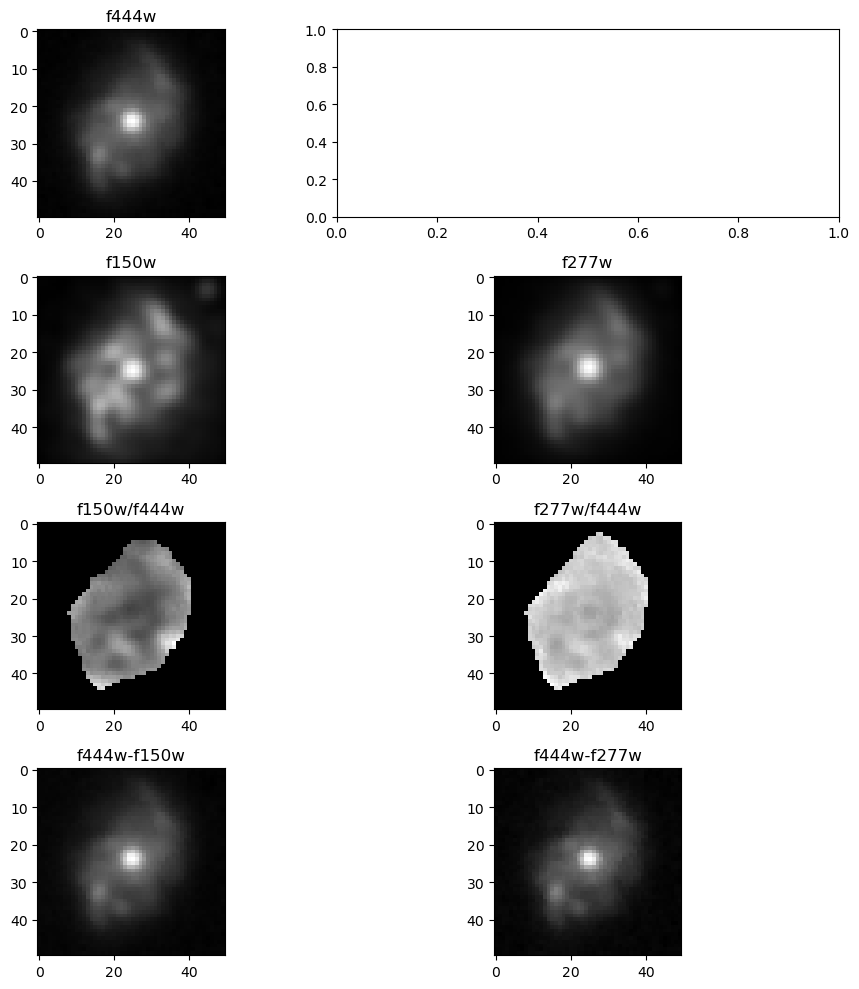

In [279]:
norm = 'linear'
idx = 9
fig, axes = plt.subplots(4, 2, figsize=(10, 10))

axes[0][0].imshow(df['f444w'][idx], cmap='gray', norm=norm)
axes[0][0].set_title('f444w')

axes[1][0].imshow(df['f150w'][idx], cmap='gray', norm=norm)
axes[1][0].set_title('f150w')

axes[1][1].imshow(df['f277w'][idx], cmap='gray', norm=norm)
axes[1][1].set_title('f277w')

axes[2][0].imshow(df['f150w/f444w'][idx], cmap='gray', norm=norm)
axes[2][0].set_title('f150w/f444w')

axes[2][1].imshow(df['f277w/f444w'][idx], cmap='gray', norm=norm)
axes[2][1].set_title('f277w/f444w')

axes[3][0].imshow(df['f444w-f150w'][idx], cmap='gray', norm=norm)
axes[3][0].set_title('f444w-f150w')

axes[3][1].imshow(df['f444w-f277w'][idx], cmap='gray', norm=norm)
axes[3][1].set_title('f444w-f277w')

plt.tight_layout()
plt.show()